# Unsupervised Learning

## 1. Import Required Libraries
Import all necessary Python libraries, such as NumPy, pandas, scikit-learn, and matplotlib, that are used in unsupervised.py.

In [1]:
import numpy as np
import pandas as pd
import re
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

## 2. Load and Preprocess Data
Load the dataset used for unsupervised learning and perform any required preprocessing steps, such as normalization or handling missing values. This includes extracting tags, handling missing product names, and preparing numeric features.

In [2]:
import sys
sys.path.append('../src')

In [5]:
embeddings_numpy_arr = np.load("data/analysis_data/embeddings.npy")
# embeddings_df = pd.DataFrame(embeddings_numpy_arr)

In [7]:
path = "data/analysis_data/only_english.csv"
only_english = pd.read_csv(path)
only_english = only_english[['product_name', 'categories_tags', 'nova_group', 'ingredients_text', 'ingredient_count', 'additives_n', 'nutriscore_score', 'monounsaturated-fat_100g','sugars_100g','polyunsaturated-fat_100g','sugar_fiber_ratio','carbohydrates_100g','fiber_100g','saturated-fat_100g','sodium_per_calorie']]
print(only_english.shape)
only_english.head()

(272809, 15)


/var/folders/7j/pj2q5pdx6g373n0pxkk0xd4r0000gn/T/ipykernel_89342/2928701028.py:2: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  only_english = pd.read_csv(path)


,product_name,categories_tags,nova_group,ingredients_text,ingredient_count,additives_n,nutriscore_score,monounsaturated-fat_100g,sugars_100g,polyunsaturated-fat_100g,sugar_fiber_ratio,carbohydrates_100g,fiber_100g,saturated-fat_100g,sodium_per_calorie
0,Hershey’s Syrup,"en:beverages-and-beverages-preparations,en:bev...",1,organ defat hemp seed powder certifi organ qua...,1,0.0,NaN,0.0,6.0,0.0,0.594059,15.00,10.000,0.0,NaN
1,Vanille-Erdbeer-Cocktail,NaN,4,sunflow seed butter roast sunflow kernel dri c...,30,4.0,NaN,0.0,0.0,0.0,NaN,8.82,0.441,0.0,NaN
2,Naturelo,NaN,4,methylcellulos color preserv flavong ount per ...,5,1.0,NaN,0.0,0.0,0.0,NaN,0.00,0.000,0.0,NaN
3,Prebiotic Fiber Gummies,"en:snacks,en:sweet-snacks,en:confectioneries,e...",4,chicori root fiber water pectin agar agar tapi...,11,6.0,NaN,0.0,0.0,0.0,NaN,0.00,0.000,0.0,NaN
4,Irish Sea Moss,NaN,4,irish sea moss extract chondru crispu hypromel...,3,2.0,NaN,0.0,0.0,0.0,NaN,0.00,0.000,0.0,NaN


In [20]:
df = only_english.copy()
embeddings = embeddings_numpy_arr.copy()

In [ ]:
# Load CSV and NPY files


# Remove outliers using Isolation Forest
from sklearn.ensemble import IsolationForest
iso = IsolationForest(contamination=0.1, random_state=42)
outlier_labels = iso.fit_predict(embeddings)
inlier_mask = outlier_labels == 1
embeddings = embeddings[inlier_mask]
df = df.iloc[inlier_mask].reset_index(drop=True)
print(f"Number of data points after Isolation Forest: {len(df)}")

# Sample only 20000 datapoints for experiments
sample_size = 20000
rng = np.random.RandomState(42)
if embeddings.shape[0] > sample_size:
    idx = rng.choice(embeddings.shape[0], sample_size, replace=False)
    embeddings = embeddings[idx]
    df = df.iloc[idx].reset_index(drop=True)

# Extract tags from categories_tags
mlb = MultiLabelBinarizer()
def extract_en_tags(tags):
    if pd.isna(tags):
        return []
    extracted = re.findall(r'en:([a-z0-9\-]+)', str(tags))
    return sorted(extracted)
df["categories_tags_extracted"] = df["categories_tags"].apply(extract_en_tags)

# Remove rows without product name and sync embeddings
mask_product_name = df["product_name"].notna()
df = df[mask_product_name]
embeddings = embeddings[mask_product_name.values]

# Remove rows with missing nova_group and sync embeddings
df["nova_group"] = pd.to_numeric(df["nova_group"], errors="coerce")
mask_nova = df["nova_group"].notna()
df = df[mask_nova]
embeddings = embeddings[mask_nova.values]

# Prepare numeric features, fill missing with 0
extra_cols = [
    'monounsaturated-fat_100g', 'sugars_100g', 'polyunsaturated-fat_100g',
    'sugar_fiber_ratio', 'carbohydrates_100g', 'fiber_100g', 'saturated-fat_100g'
 ]
for col in extra_cols:
    if col not in df.columns:
        df[col] = 0
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
extra_arr = df[extra_cols].values

# Compress embeddings with PCA
from sklearn.decomposition import PCA
pca_embed = PCA(n_components=10, random_state=42)
embeddings_compressed = pca_embed.fit_transform(embeddings)

# Prepare features for clustering
X_tags = mlb.fit_transform(df["categories_tags_extracted"])
nova_arr = df["nova_group"].values.reshape(-1, 1)
X_combined = np.hstack([X_tags, nova_arr, extra_arr, embeddings])
print('Original X_combined shape:', X_combined.shape)

# Compress X_combined with PCA to make GMM feasible
pca_final = PCA(n_components=50, random_state=42)  # You can adjust n_components as needed
X_combined_reduced = pca_final.fit_transform(X_combined)
print('Reduced X_combined shape:', X_combined_reduced.shape)

# Further reduce to 3D for visualization
pca_vis = PCA(n_components=3, random_state=1)
X_pca = pca_vis.fit_transform(X_combined_reduced)
print('X_pca shape (for visualization):', X_pca.shape)

Number of data points after Isolation Forest: 245528
Original X_combined shape: (19903, 1771)
Reduced X_combined shape: (19903, 50)
X_pca shape (for visualization): (19903, 3)


## 3. Kmeans and evaluation
Set up the unsupervised learning algorithm (KMeans) and explain the choice of parameters and model configuration.

In [ ]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
# k_values = [3, 4, 5, 6, 7, 8, 9, 10, 15, 20, 25, 50, 75, 100, 125, 150]
k_values = [7]
kmeans_metrics = {
    "k": [],
    "inertia": [],
    "silhouette": [],
    "calinski_harabasz": [],
    "davies_bouldin": []
}

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_combined)
    kmeans_metrics["k"].append(k)
    kmeans_metrics["inertia"].append(kmeans.inertia_)
    kmeans_metrics["silhouette"].append(silhouette_score(X_combined, labels))
    kmeans_metrics["calinski_harabasz"].append(calinski_harabasz_score(X_combined, labels))
    kmeans_metrics["davies_bouldin"].append(davies_bouldin_score(X_combined, labels))
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    cmap4 = ListedColormap(plt.get_cmap('tab10').colors[:k])
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=labels, cmap=cmap4, s=20)
    cbar = plt.colorbar(scatter, label='Cluster', ticks=list(range(k)))
    cbar.set_ticks(list(range(k)))
    cbar.set_ticklabels([str(i) for i in range(k)])
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.set_zlabel('PC3')
    plt.title(f'KMeans Clusters (PCA 3D, k={k})')
    plt.savefig(f'pca_kmeans_k{k}.png')
    plt.close(fig)

kmeans_df = pd.DataFrame(kmeans_metrics)
display(kmeans_df)

# Combined elbow curves for KMeans as subplots
# fig, axs = plt.subplots(2, 2, figsize=(14, 10))
# axs[0, 0].plot(kmeans_df['k'], kmeans_df['inertia'], marker='o')
# axs[0, 0].set_title('KMeans Elbow Curve (Inertia)')
# axs[0, 0].set_xlabel('Number of clusters (k)')
# axs[0, 0].set_ylabel('Inertia')
# axs[0, 0].grid(True)

# axs[0, 1].plot(kmeans_df['k'], kmeans_df['silhouette'], marker='o', color='green')
# axs[0, 1].set_title('KMeans Elbow Curve (Silhouette)')
# axs[0, 1].set_xlabel('Number of clusters (k)')
# axs[0, 1].set_ylabel('Silhouette Score')
# axs[0, 1].grid(True)

# axs[1, 0].plot(kmeans_df['k'], kmeans_df['calinski_harabasz'], marker='o', color='blue')
# axs[1, 0].set_title('KMeans Elbow Curve (Calinski-Harabasz)')
# axs[1, 0].set_xlabel('Number of clusters (k)')
# axs[1, 0].set_ylabel('Calinski-Harabasz Score')
# axs[1, 0].grid(True)

# axs[1, 1].plot(kmeans_df['k'], kmeans_df['davies_bouldin'], marker='o', color='red')
# axs[1, 1].set_title('KMeans Elbow Curve (Davies-Bouldin)')
# axs[1, 1].set_xlabel('Number of clusters (k)')
# axs[1, 1].set_ylabel('Davies-Bouldin Index')
# axs[1, 1].grid(True)

# plt.tight_layout()
# plt.show()

,k,inertia,silhouette,calinski_harabasz,davies_bouldin
0,7,1.919029e+08,0.765931,30575.223978,0.479011


<Figure size 640x480 with 0 Axes>

In [15]:
df['cluster_id'] = labels
df.head()

,product_name,categories_tags,nova_group,ingredients_text,ingredient_count,additives_n,nutriscore_score,monounsaturated-fat_100g,sugars_100g,polyunsaturated-fat_100g,sugar_fiber_ratio,carbohydrates_100g,fiber_100g,saturated-fat_100g,sodium_per_calorie,categories_tags_extracted,cluster_id
0,Breakfast bakes,en:meals,4,shred potato potato dextros disodium pyrophsph...,54,9.0,2.0,0.0,1.01,0.00,0.480952,18.18,2.00,2.53,0.000993,[meals],0
2,"Lemon sandwich creme cookies, lemon","en:snacks,en:sweet-snacks,en:biscuits-and-cake...",4,enrich wheat flour wheat flour niacin reduc ir...,18,5.0,26.0,0.0,37.14,0.00,371.400000,68.57,0.00,7.14,0.000630,"[biscuits, biscuits-and-cakes, snacks, sweet-s...",6
3,Icing decorations,en:baking-decorations,4,sugar corn syrup corn starch xanthan gum water...,21,11.0,21.0,0.0,100.00,0.00,0.000000,100.00,0.00,0.00,0.000000,[baking-decorations],0
4,Lucky Charms,"en:plant-based-foods-and-beverages,en:plant-ba...",4,wvhole grain oat sugar corn starch madifi corn...,27,3.0,NaN,0.0,0.00,0.00,0.000000,0.00,0.00,0.00,NaN,"[breakfast-cereals, breakfasts, cereals-and-po...",0
5,9 Grain Half Loaf Bread,NaN,4,enrich wheat flour flour malt barley flour red...,29,2.0,NaN,0.0,7.14,1.79,1.945504,46.40,3.57,0.00,0.001554,[],0


In [16]:
df['cluster_id'].value_counts()


cluster_id
0    17427
6     1713
1      607
5      124
2       19
4       10
3        3
Name: count, dtype: int64

In [17]:
df.to_csv("cluster_results_v3.csv")

In [21]:
# try running on entire data - compress embeddings

# Load CSV and NPY files


# Remove outliers using Isolation Forest
# from sklearn.ensemble import IsolationForest
# iso = IsolationForest(contamination=0.1, random_state=42)
# outlier_labels = iso.fit_predict(embeddings)
# inlier_mask = outlier_labels == 1
# embeddings = embeddings[inlier_mask]
# df = df.iloc[inlier_mask].reset_index(drop=True)
# print(f"Number of data points after Isolation Forest: {len(df)}")

# Sample only 20000 datapoints for experiments
# sample_size = 20000
# rng = np.random.RandomState(42)
# if embeddings.shape[0] > sample_size:
#     idx = rng.choice(embeddings.shape[0], sample_size, replace=False)
#     embeddings = embeddings[idx]
#     df = df.iloc[idx].reset_index(drop=True)

# Extract tags from categories_tags
mlb = MultiLabelBinarizer()
def extract_en_tags(tags):
    if pd.isna(tags):
        return []
    extracted = re.findall(r'en:([a-z0-9\-]+)', str(tags))
    return sorted(extracted)
df["categories_tags_extracted"] = df["categories_tags"].apply(extract_en_tags)

# Remove rows without product name and sync embeddings
mask_product_name = df["product_name"].notna()
df = df[mask_product_name]
embeddings = embeddings[mask_product_name.values]

# Remove rows with missing nova_group and sync embeddings
df["nova_group"] = pd.to_numeric(df["nova_group"], errors="coerce")
mask_nova = df["nova_group"].notna()
df = df[mask_nova]
embeddings = embeddings[mask_nova.values]

# Prepare numeric features, fill missing with 0
extra_cols = [
    'monounsaturated-fat_100g', 'sugars_100g', 'polyunsaturated-fat_100g',
    'sugar_fiber_ratio', 'carbohydrates_100g', 'fiber_100g', 'saturated-fat_100g'
 ]
for col in extra_cols:
    if col not in df.columns:
        df[col] = 0
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
extra_arr = df[extra_cols].values

# Compress embeddings with PCA
from sklearn.decomposition import PCA
pca_embed = PCA(n_components=10, random_state=42)
embeddings_compressed = pca_embed.fit_transform(embeddings)

# Prepare features for clustering
X_tags = mlb.fit_transform(df["categories_tags_extracted"])
nova_arr = df["nova_group"].values.reshape(-1, 1)
X_combined = np.hstack([X_tags, nova_arr, extra_arr, embeddings])
print('Original X_combined shape:', X_combined.shape)

# Compress X_combined with PCA to make GMM feasible
pca_final = PCA(n_components=50, random_state=42)  # You can adjust n_components as needed
X_combined_reduced = pca_final.fit_transform(X_combined)
print('Reduced X_combined shape:', X_combined_reduced.shape)

# Further reduce to 3D for visualization
pca_vis = PCA(n_components=3, random_state=1)
X_pca = pca_vis.fit_transform(X_combined_reduced)
print('X_pca shape (for visualization):', X_pca.shape)

Original X_combined shape: (271525, 5633)


: 

## 4. DBSCAN Clustering and Outlier Detection
Apply DBSCAN for clustering and use PCA for visualization. Outliers will be identified as points labeled -1 by DBSCAN.

In [4]:
from sklearn.cluster import DBSCAN

# Sample the dataset for DBSCAN to improve speed
sample_size = 10000  # Adjust as needed
rng = np.random.RandomState(42)
if X_combined.shape[0] > sample_size:
    idx = rng.choice(X_combined.shape[0], sample_size, replace=False)
    X_dbscan = X_combined[idx]
    df_dbscan = df.iloc[idx].copy()
else:
    X_dbscan = X_combined
    df_dbscan = df.copy()

# Fit DBSCAN
clustering = DBSCAN(eps=2.0, min_samples=10).fit(X_dbscan)
dbscan_labels = clustering.labels_
df_dbscan['dbscan_cluster'] = dbscan_labels

# Identify outliers (label == -1)
outliers = df_dbscan[dbscan_labels == -1]
print(f"Number of outliers detected by DBSCAN: {len(outliers)}")

Number of outliers detected by DBSCAN: 8399


In [5]:
# PCA for DBSCAN visualization
pca = PCA(n_components=3, random_state=42)
X_pca_dbscan = pca.fit_transform(X_dbscan)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
# Use a colormap that highlights outliers (-1)
unique_labels = np.unique(dbscan_labels)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))
for i, label in enumerate(unique_labels):
    mask = dbscan_labels == label
    ax.scatter(X_pca_dbscan[mask, 0], X_pca_dbscan[mask, 1], X_pca_dbscan[mask, 2],
               c=[colors[i]], label=f'Cluster {label}', s=20)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
plt.title('DBSCAN Clusters (PCA 3D)')
plt.legend()
plt.savefig(f'pca_DBSCAN.png')
plt.close(fig)

## 5. Gaussian Mixture Model (GMM) Clustering
Apply Gaussian Mixture Model (GMM) clustering to the data, evaluate with metrics (BIC, AIC, Silhouette, Calinski-Harabasz, Davies-Bouldin), and visualize the clusters in PCA space.

,k,bic,aic,silhouette,calinski_harabasz,davies_bouldin
0,3,-9.988515e+05,-1.030264e+06,0.000325,1340.814318,2.731240
1,4,-1.067046e+06,-1.108933e+06,-0.052308,5404.142313,2.011601
2,5,-1.443196e+05,-1.966796e+05,0.499958,7940.464887,3.938287
3,6,-1.333218e+05,-1.961554e+05,0.494127,7272.066814,2.936362
4,7,-2.618042e+05,-3.351114e+05,0.372090,6536.500525,2.351976
5,8,-3.647573e+05,-4.485380e+05,0.319276,5635.935828,2.576871
6,9,-1.406918e+06,-1.501172e+06,0.081295,5411.418441,2.321984
7,10,-1.621658e+06,-1.726385e+06,0.073502,4972.587055,2.354170
8,15,-1.949494e+06,-2.106590e+06,-0.006155,6029.220025,4.174440
9,20,-2.238477e+06,-2.447941e+06,-0.092069,4087.937948,5.455120


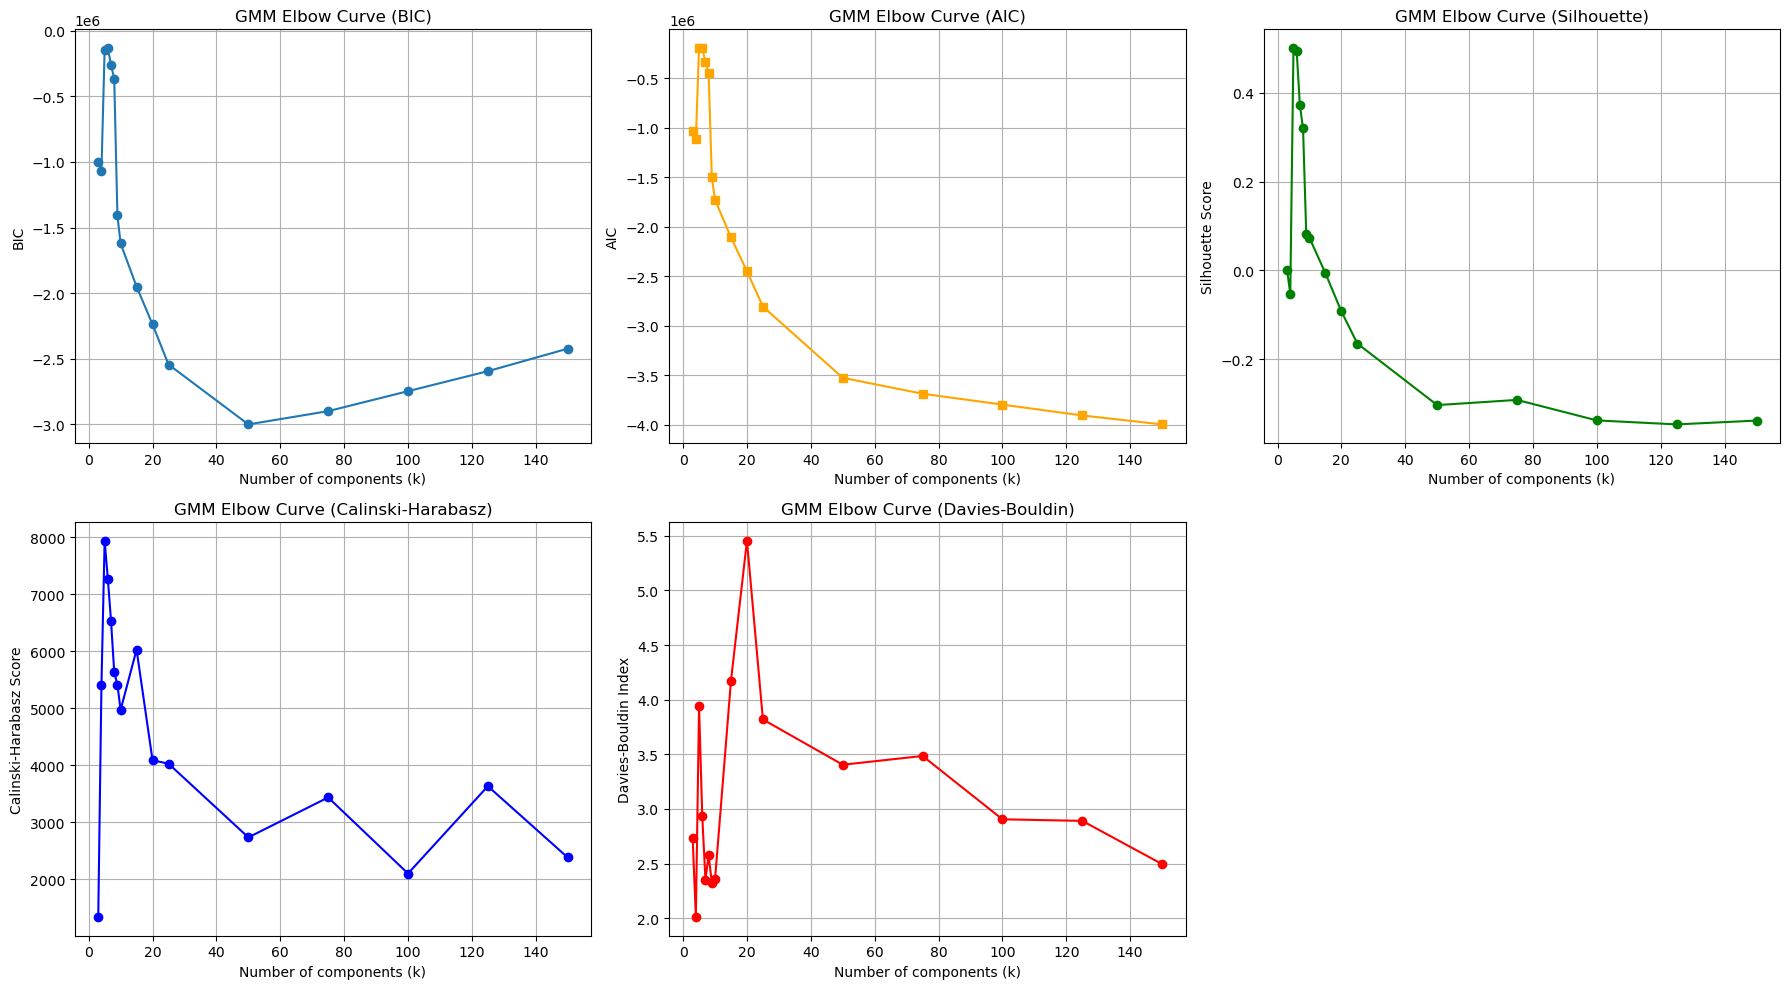

In [6]:
from sklearn.mixture import GaussianMixture
gmm_k_values = [3, 4, 5, 6, 7, 8, 9, 10, 15, 20, 25, 50, 75, 100, 125, 150]
gmm_metrics = {
    "k": [],
    "bic": [],
    "aic": [],
    "silhouette": [],
    "calinski_harabasz": [],
    "davies_bouldin": []
}
n_samples = X_combined_reduced.shape[0]
# To avoid O(n^2) silhouette computation on large datasets, compute on a sample
max_silhouette_samples = 5000
sample_size = min(max_silhouette_samples, n_samples)
rng = np.random.RandomState(42)

for k in gmm_k_values:
    gmm = GaussianMixture(n_components=k, covariance_type='full', random_state=42)
    gmm.fit(X_combined_reduced)
    labels_gmm = gmm.predict(X_combined_reduced)
    bic = gmm.bic(X_combined_reduced)
    aic = gmm.aic(X_combined_reduced)
    calinski = calinski_harabasz_score(X_combined_reduced, labels_gmm)
    davies = davies_bouldin_score(X_combined_reduced, labels_gmm)
    if n_samples > sample_size:
        idx = rng.choice(n_samples, sample_size, replace=False)
        sil = silhouette_score(X_combined_reduced[idx], labels_gmm[idx])
    else:
        sil = silhouette_score(X_combined_reduced, labels_gmm)
    gmm_metrics["k"].append(k)
    gmm_metrics["bic"].append(bic)
    gmm_metrics["aic"].append(aic)
    gmm_metrics["silhouette"].append(sil)
    gmm_metrics["calinski_harabasz"].append(calinski)
    gmm_metrics["davies_bouldin"].append(davies)
    fig = plt.figure(figsize=(8,6))
    ax = fig.add_subplot(111, projection='3d')
    cmap4 = ListedColormap(plt.get_cmap('tab10').colors[:k])
    scatter = ax.scatter(X_combined_reduced[:, 0], X_combined_reduced[:, 1], X_combined_reduced[:, 2], c=labels_gmm, cmap=cmap4, s=20)
    cbar = plt.colorbar(scatter, label='GMM Cluster', ticks=list(range(k)))
    cbar.set_ticklabels([str(i) for i in range(k)])
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.set_zlabel('PC3')
    plt.title(f'GMM Clusters (PCA 3D, k={k})')
    plt.savefig(f'pca_gmm_k{k}.png')
    plt.close(fig)

gmm_df = pd.DataFrame(gmm_metrics)
display(gmm_df)

# Combined elbow curves for GMM as subplots
fig, axs = plt.subplots(2, 3, figsize=(18, 10))
axs[0, 0].plot(gmm_df['k'], gmm_df['bic'], marker='o')
axs[0, 0].set_title('GMM Elbow Curve (BIC)')
axs[0, 0].set_xlabel('Number of components (k)')
axs[0, 0].set_ylabel('BIC')
axs[0, 0].grid(True)

axs[0, 1].plot(gmm_df['k'], gmm_df['aic'], marker='s', color='orange')
axs[0, 1].set_title('GMM Elbow Curve (AIC)')
axs[0, 1].set_xlabel('Number of components (k)')
axs[0, 1].set_ylabel('AIC')
axs[0, 1].grid(True)

axs[0, 2].plot(gmm_df['k'], gmm_df['silhouette'], marker='o', color='green')
axs[0, 2].set_title('GMM Elbow Curve (Silhouette)')
axs[0, 2].set_xlabel('Number of components (k)')
axs[0, 2].set_ylabel('Silhouette Score')
axs[0, 2].grid(True)

axs[1, 0].plot(gmm_df['k'], gmm_df['calinski_harabasz'], marker='o', color='blue')
axs[1, 0].set_title('GMM Elbow Curve (Calinski-Harabasz)')
axs[1, 0].set_xlabel('Number of components (k)')
axs[1, 0].set_ylabel('Calinski-Harabasz Score')
axs[1, 0].grid(True)

axs[1, 1].plot(gmm_df['k'], gmm_df['davies_bouldin'], marker='o', color='red')
axs[1, 1].set_title('GMM Elbow Curve (Davies-Bouldin)')
axs[1, 1].set_xlabel('Number of components (k)')
axs[1, 1].set_ylabel('Davies-Bouldin Index')
axs[1, 1].grid(True)

fig.delaxes(axs[1, 2])
plt.tight_layout()
plt.show()

## 6. Hierarchical Clustering

,k,silhouette,calinski_harabasz,davies_bouldin
0,3,0.833697,26608.694626,0.458808
1,4,0.820226,27555.958678,0.476821
2,5,0.816731,28783.723495,0.473130
3,6,0.699226,30898.253041,0.530685
4,7,0.695154,32790.858344,0.466126
5,8,0.697946,32151.874360,0.488168
6,9,0.702787,32599.840010,0.473047
7,10,0.697395,34134.001986,0.469002
8,15,0.472547,47985.636417,0.533054
9,20,0.432099,55312.868834,0.626619


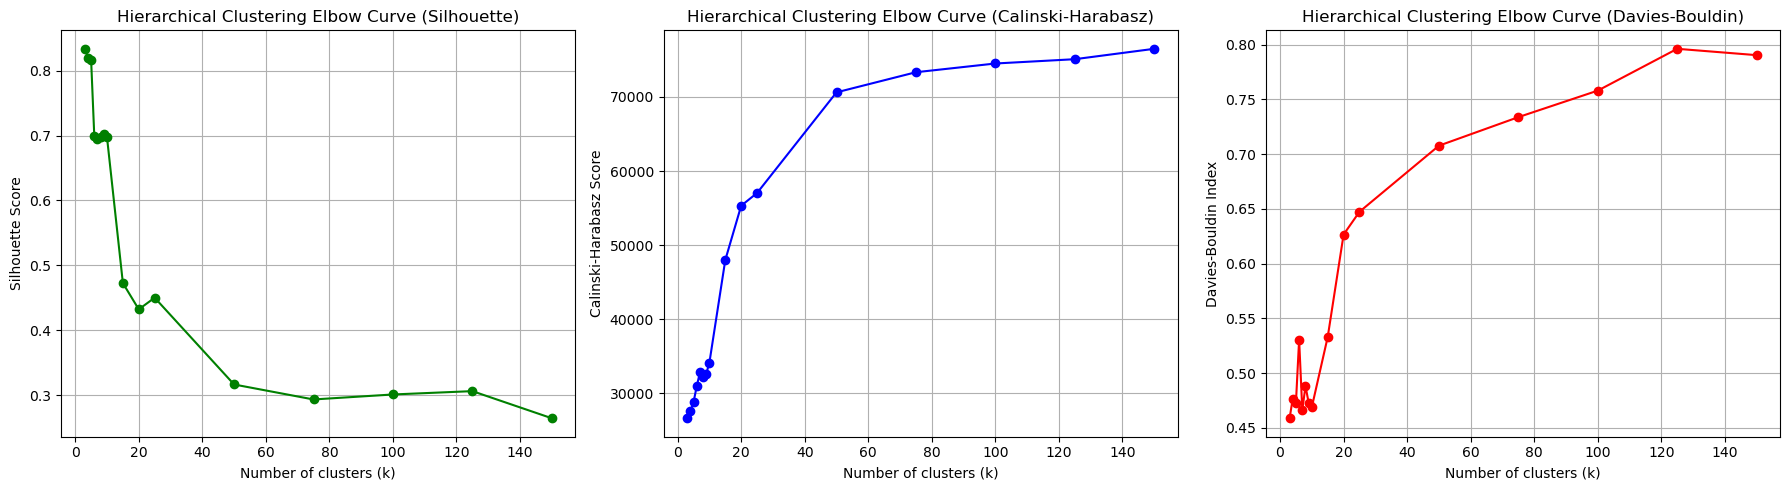

In [7]:
from sklearn.cluster import AgglomerativeClustering
hier_k_values = [3, 4, 5, 6, 7, 8, 9, 10, 15, 20, 25, 50, 75, 100, 125, 150]
hier_metrics = {
    "k": [],
    "silhouette": [],
    "calinski_harabasz": [],
    "davies_bouldin": []
}
X_hier = X_combined_reduced
X_pca_hier = X_pca

for k in hier_k_values:
    hier = AgglomerativeClustering(n_clusters=k)
    labels_hier = hier.fit_predict(X_hier)
    calinski = calinski_harabasz_score(X_hier, labels_hier)
    davies = davies_bouldin_score(X_hier, labels_hier)
    n_samples = X_hier.shape[0]
    max_silhouette_samples = 5000
    sample_size_sil = min(max_silhouette_samples, n_samples)
    if n_samples > sample_size_sil:
        idx_sil = rng.choice(n_samples, sample_size_sil, replace=False)
        sil = silhouette_score(X_hier[idx_sil], labels_hier[idx_sil])
    else:
        sil = silhouette_score(X_hier, labels_hier)
    hier_metrics["k"].append(k)
    hier_metrics["silhouette"].append(sil)
    hier_metrics["calinski_harabasz"].append(calinski)
    hier_metrics["davies_bouldin"].append(davies)
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    cmap4 = ListedColormap(plt.get_cmap('tab10').colors[:k])
    scatter = ax.scatter(X_pca_hier[:, 0], X_pca_hier[:, 1], X_pca_hier[:, 2], c=labels_hier, cmap=cmap4, s=20)
    cbar = plt.colorbar(scatter, label='Hier Cluster', ticks=list(range(k)))
    cbar.set_ticklabels([str(i) for i in range(k)])
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.set_zlabel('PC3')
    plt.title(f'Hierarchical Clusters (PCA 3D, k={k})')
    plt.savefig(f'pca_hierarchical_k{k}.png')
    plt.close(fig)

hier_df = pd.DataFrame(hier_metrics)
display(hier_df)

# Combined elbow curves for Hierarchical as subplots
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].plot(hier_df['k'], hier_df['silhouette'], marker='o', color='green')
axs[0].set_title('Hierarchical Clustering Elbow Curve (Silhouette)')
axs[0].set_xlabel('Number of clusters (k)')
axs[0].set_ylabel('Silhouette Score')
axs[0].grid(True)

axs[1].plot(hier_df['k'], hier_df['calinski_harabasz'], marker='o', color='blue')
axs[1].set_title('Hierarchical Clustering Elbow Curve (Calinski-Harabasz)')
axs[1].set_xlabel('Number of clusters (k)')
axs[1].set_ylabel('Calinski-Harabasz Score')
axs[1].grid(True)

axs[2].plot(hier_df['k'], hier_df['davies_bouldin'], marker='o', color='red')
axs[2].set_title('Hierarchical Clustering Elbow Curve (Davies-Bouldin)')
axs[2].set_xlabel('Number of clusters (k)')
axs[2].set_ylabel('Davies-Bouldin Index')
axs[2].grid(True)

plt.tight_layout()
plt.show()